# Loan Default Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report,
                              precision_recall_curve)
import joblib

sns.set_style("whitegrid")
RANDOM_STATE = 42


In [2]:
# loading the dataset
df = pd.read_csv("data/loan_train.csv")
print(df.shape)
df.head()


(27003, 47)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


In [3]:
# checking class balance - most loans are paid, only ~15% default
df["loan_status"].value_counts(normalize=True)


loan_status
0    0.85272
1    0.14728
Name: proportion, dtype: float64

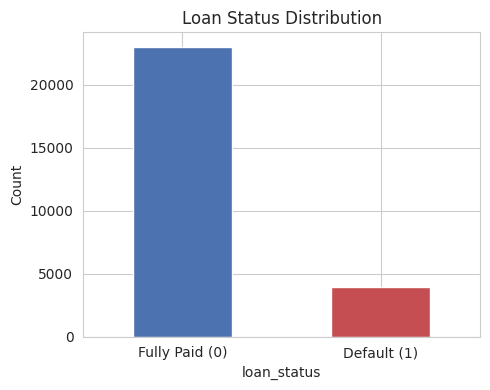

In [4]:
plt.figure(figsize=(5,4))
df["loan_status"].value_counts().plot(kind="bar", color=["#4C72B0","#C44E52"])
plt.xticks([0,1], ["Fully Paid (0)", "Default (1)"], rotation=0)
plt.ylabel("Count")
plt.title("Loan Status Distribution")
plt.tight_layout()
plt.savefig("images/target_distribution.png", dpi=120)
plt.show()


In [5]:
# dropping columns that only exist after the loan has already been funded/repaid
# (using these would be data leakage - model would basically be seeing the answer)
leakage_cols = [
    "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee", "last_pymnt_d",
    "last_pymnt_amnt", "last_credit_pull_d"
]

# ids / free text / not useful for prediction
drop_cols = ["id", "member_id", "url", "desc", "emp_title", "title", "zip_code", "funded_amnt_inv"]

df = df.drop(columns=leakage_cols + drop_cols)
print(df.shape)


(27003, 27)


In [6]:
# term: "36 months" -> 36
df["term"] = df["term"].str.replace(" months", "", regex=False).astype(int)

# int_rate / revol_util: "13.23%" -> 13.23
df["int_rate"] = df["int_rate"].str.replace("%", "", regex=False).astype(float)
df["revol_util"] = pd.to_numeric(df["revol_util"].astype(str).str.replace("%", "", regex=False), errors="coerce")

# emp_length: turning text buckets into numbers
emp_map = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10}
df["emp_length"] = df["emp_length"].map(emp_map)

# new feature: how many years of credit history they had at time of loan
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%y", errors="coerce")
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%y", errors="coerce")
df["credit_history_years"] = (df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25
df = df.drop(columns=["issue_d", "earliest_cr_line"])

# these two cols were 60-90% empty, just turning them into simple yes/no flags instead
df["has_prior_record"] = df["mths_since_last_record"].notna().astype(int)
df["has_prior_delinq"] = df["mths_since_last_delinq"].notna().astype(int)
df = df.drop(columns=["mths_since_last_record", "mths_since_last_delinq"])

print(df.shape)
df.head()


(27003, 26)


,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,...,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,pub_rec_bankruptcies,credit_history_years,has_prior_record,has_prior_delinq
0,10000,10000,36,13.23,338.05,C,C1,4.0,RENT,37000.0,...,0,9,0,10217,62.7,14,0.0,7.830253,0,1
1,14000,14000,36,7.88,437.94,A,A5,0.0,RENT,105000.0,...,0,9,0,13307,28.8,18,0.0,5.169062,0,0
2,9475,9475,36,8.94,301.04,A,A5,9.0,OWN,27000.0,...,0,5,0,7866,44.7,17,0.0,10.505133,0,0
3,4000,4000,36,7.29,124.04,A,A4,10.0,OWN,35000.0,...,0,13,0,29358,69.1,18,0.0,13.330595,0,0
4,3600,3600,36,6.62,110.54,A,A2,1.0,RENT,60000.0,...,1,12,0,15502,70.1,32,0.0,12.668036,0,0


In [7]:
y = df["loan_status"]
X = df.drop(columns=["loan_status"])

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)


(21602, 25) (5401, 25)


In [8]:
# numeric cols: fill missing with median, then scale
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# categorical cols: fill missing with most common value, then one-hot encode
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])


In [9]:
# comparing 3 models, all set up to handle the class imbalance
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                             max_depth=10, min_samples_leaf=5,
                                             random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                              scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                              eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)
}

fitted_pipes = {}
results = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted_pipes[name] = pipe

    proba = pipe.predict_proba(X_test)[:, 1]
    pred_default = pipe.predict(X_test)

    # finding the probability cutoff that gives the best F1, instead of just using 0.5
    prec, rec, thr = precision_recall_curve(y_test, proba)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    best_idx = np.argmax(f1s[:-1])
    best_thr = thr[best_idx]
    pred_tuned = (proba >= best_thr).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Accuracy@0.5": accuracy_score(y_test, pred_default),
        "F1@0.5": f1_score(y_test, pred_default),
        "Best Threshold": best_thr,
        "Accuracy@BestThr": accuracy_score(y_test, pred_tuned),
        "Precision@BestThr": precision_score(y_test, pred_tuned),
        "Recall@BestThr": recall_score(y_test, pred_tuned),
        "F1@BestThr": f1_score(y_test, pred_tuned),
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
results_df


,Model,ROC-AUC,Accuracy@0.5,F1@0.5,Best Threshold,Accuracy@BestThr,Precision@BestThr,Recall@BestThr,F1@BestThr
0,Logistic Regression,0.709114,0.656360,0.356003,0.539856,0.712646,0.274836,0.581132,0.373183
2,XGBoost,0.706402,0.697093,0.355398,0.516178,0.718941,0.272498,0.544654,0.363255
1,Random Forest,0.704019,0.691909,0.358520,0.507862,0.708572,0.265785,0.555975,0.359642


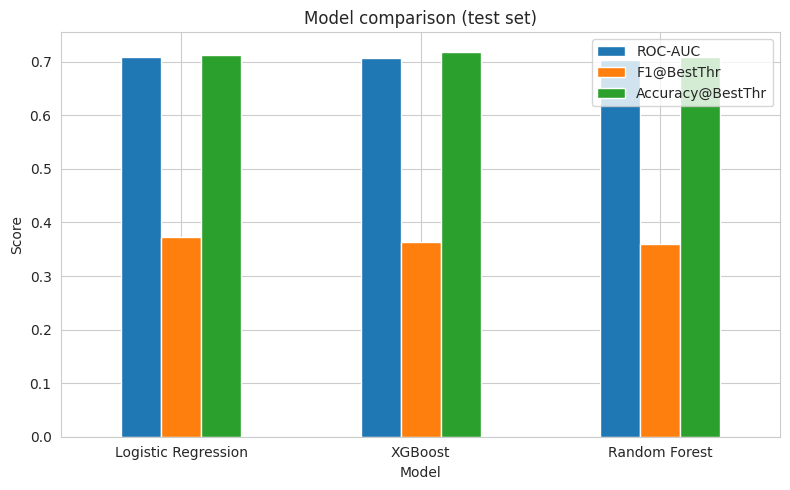

In [10]:
results_df.set_index("Model")[["ROC-AUC","F1@BestThr","Accuracy@BestThr"]].plot(
    kind="bar", figsize=(8,5), rot=0)
plt.title("Model comparison (test set)")
plt.ylabel("Score")
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=120)
plt.show()


best model: Logistic Regression | threshold: 0.54
              precision    recall  f1-score   support

  Fully Paid       0.91      0.74      0.81      4606
     Default       0.27      0.58      0.37       795

    accuracy                           0.71      5401
   macro avg       0.59      0.66      0.59      5401
weighted avg       0.82      0.71      0.75      5401



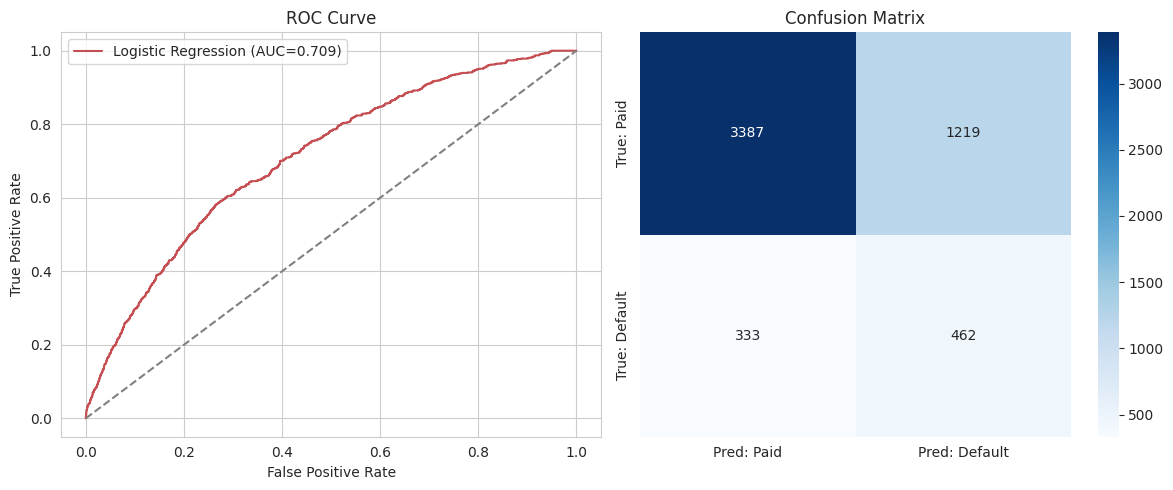

In [11]:
best_name = results_df.iloc[0]["Model"]
best_pipe = fitted_pipes[best_name]
best_thr = results_df.iloc[0]["Best Threshold"]
print("best model:", best_name, "| threshold:", round(best_thr, 3))

proba = best_pipe.predict_proba(X_test)[:, 1]
pred = (proba >= best_thr).astype(int)
print(classification_report(y_test, pred, target_names=["Fully Paid","Default"]))

fig, axes = plt.subplots(1, 2, figsize=(12,5))

fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, label=f"{best_name} (AUC={roc_auc_score(y_test, proba):.3f})", color="#C44E52")
axes[0].plot([0,1],[0,1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: Paid","Pred: Default"],
            yticklabels=["True: Paid","True: Default"], ax=axes[1])
axes[1].set_title("Confusion Matrix")

plt.tight_layout()
plt.savefig("images/roc_confusion.png", dpi=120)
plt.show()


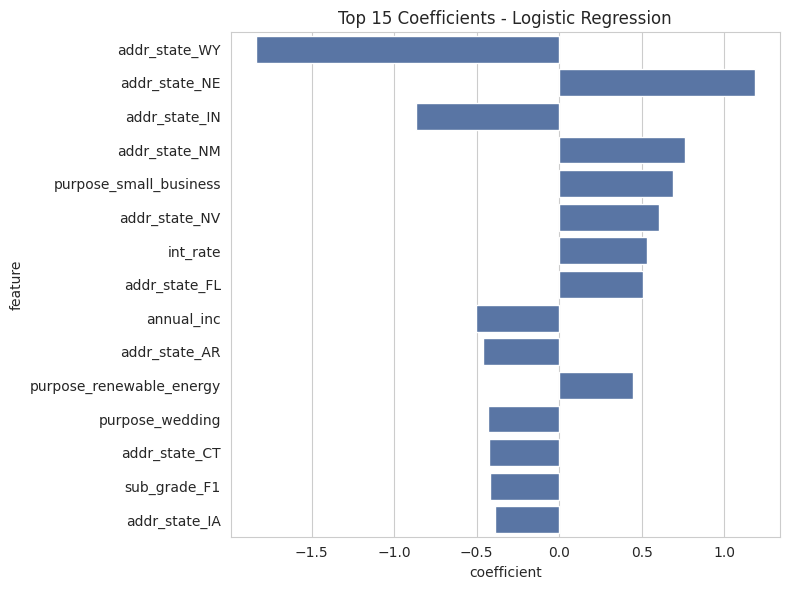

In [12]:
# which features matter most
if best_name in ["Random Forest", "XGBoost"]:
    ohe = best_pipe.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
    feat_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
    importances = best_pipe.named_steps["model"].feature_importances_
    imp_df = pd.DataFrame({"feature": feat_names, "importance": importances})
    imp_df = imp_df.sort_values("importance", ascending=False).head(15)

    plt.figure(figsize=(8,6))
    sns.barplot(data=imp_df, x="importance", y="feature", color="#4C72B0")
    plt.title(f"Top 15 Feature Importances - {best_name}")
    plt.tight_layout()
    plt.savefig("images/feature_importance.png", dpi=120)
    plt.show()
else:
    coefs = best_pipe.named_steps["model"].coef_[0]
    ohe = best_pipe.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
    feat_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
    imp_df = pd.DataFrame({"feature": feat_names, "coefficient": coefs})
    imp_df["abs_coef"] = imp_df["coefficient"].abs()
    imp_df = imp_df.sort_values("abs_coef", ascending=False).head(15)

    plt.figure(figsize=(8,6))
    sns.barplot(data=imp_df, x="coefficient", y="feature", color="#4C72B0")
    plt.title(f"Top 15 Coefficients - {best_name}")
    plt.tight_layout()
    plt.savefig("images/feature_importance.png", dpi=120)
    plt.show()


In [13]:
# saving the trained pipeline so it doesn't need to be retrained every time
joblib.dump({"pipeline": best_pipe, "threshold": best_thr, "model_name": best_name},
            "models/loan_default_model.pkl")
print("saved:", best_name, "| threshold:", round(best_thr, 3))


saved: Logistic Regression | threshold: 0.54


In [14]:
# loading it back and testing on one applicant, like a new loan request would come in
loaded = joblib.load("models/loan_default_model.pkl")
sample = X_test.iloc[[0]]
prob_default = loaded["pipeline"].predict_proba(sample)[0, 1]
decision = "HIGH RISK - Review/Reject" if prob_default >= loaded["threshold"] else "LOW RISK - Approve"

print(f"probability of default: {prob_default:.2%}")
print(f"threshold: {loaded['threshold']:.2%}")
print(f"decision: {decision}")
print(f"actual outcome: {'Defaulted' if y_test.iloc[0]==1 else 'Fully Paid'}")


probability of default: 23.66%
threshold: 53.99%
decision: LOW RISK - Approve
actual outcome: Fully Paid
